# 05c · Variação entre sementes

Treina as configurações finais do notebook 05b com três sementes (42, 7 e 123) e reporta média e desvio-padrão. Só a semente muda entre as execuções, o que afeta a inicialização dos pesos e a ordem dos *batches*.

As múltiplas sementes foram adotadas porque, na primeira rodada, a ordem entre a CNN e o Transformer na validação mudava conforme a semente (Apêndice B do TCC, Seção B.2). Os modelos treinados aqui são os avaliados no notebook 06.

O conjunto de teste não é usado aqui. Precisa de GPU (T4); os nove treinamentos levam menos de 10 minutos.

In [ ]:
import os, json, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

DATA_DIR   = '/content/drive/MyDrive/TCC-Exoplanetas'
MODELS_DIR = f'{DATA_DIR}/modelos'
SEMENTES_DIR = f'{MODELS_DIR}/sementes'
os.makedirs(SEMENTES_DIR, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
if device == 'cpu':
    print('*** ATENCAO: ative Runtime -> T4 GPU. ***')

SEMENTES = [42, 7, 123]      # 42 e a semente primaria (reproduz a busca)
BATCH_SIZE, MAX_EPOCAS, PACIENCIA, CLIP_NORMA = 64, 50, 8, 1.0

Mounted at /content/drive
device: cuda


## 1. Configurações finais

Lidas do `config_final.json` gerado no notebook 05b ou, se ele não existir, deduzidas do `busca_resultados.json`.

In [ ]:
cfg_path = f'{MODELS_DIR}/config_final.json'
res_path = f'{MODELS_DIR}/busca_resultados.json'

if os.path.exists(cfg_path):
    cf = json.load(open(cfg_path))
    VENCEDORAS = {s: {'lr': v['lr'], 'ramo': v['ramo']} for s, v in cf.items()}
    print('Configuracoes lidas de config_final.json')
else:
    res = json.load(open(res_path))
    VENCEDORAS = {}
    for slug in ['cnn1d', 'bilstm', 'transformer']:
        cands = {k: v for k, v in res.items() if v['slug'] == slug}
        melhor = min(cands, key=lambda k: cands[k]['melhor_val'])
        VENCEDORAS[slug] = cands[melhor]['cfg']
    print('Configuracoes deduzidas de busca_resultados.json')

for s, c in VENCEDORAS.items():
    print(f'  {s:12s} lr={c["lr"]}  {c["ramo"]}')

Configuracoes lidas de config_final.json
  cnn1d        lr=0.001  {'base': 16}
  bilstm       lr=0.001  {'hidden': 32, 'camadas': 1}
  transformer  lr=0.0003  {'d_model': 64, 'camadas': 2}


In [ ]:
d = np.load(f'{DATA_DIR}/dataset.npz')

class VisoesDataset(Dataset):
    def __init__(self, Xg, Xl, y):
        self.Xg = torch.from_numpy(Xg).float().unsqueeze(1)
        self.Xl = torch.from_numpy(Xl).float().unsqueeze(1)
        self.y  = torch.from_numpy(y).float()
    def __len__(self):  return len(self.y)
    def __getitem__(self, i): return self.Xg[i], self.Xl[i], self.y[i]

ds_train = VisoesDataset(d['Xg_train'], d['Xl_train'], d['y_train'])
ds_val   = VisoesDataset(d['Xg_val'],   d['Xl_val'],   d['y_val'])
print(f'treino {len(ds_train)} | val {len(ds_val)}')

treino 6312 | val 683


## 2. Arquiteturas

As mesmas do notebook 05b.

In [ ]:
class DoisRamos(nn.Module):
    def __init__(self, fabrica_ramo, p_dropout=0.3):
        super().__init__()
        self.ramo_global = fabrica_ramo(); self.ramo_local = fabrica_ramo()
        d_ = self.ramo_global.out_dim
        self.cabeca = nn.Sequential(
            nn.Linear(2 * d_, 64), nn.ReLU(), nn.Dropout(p_dropout), nn.Linear(64, 1))
    def forward(self, g, l):
        return self.cabeca(torch.cat([self.ramo_global(g), self.ramo_local(l)], 1)).squeeze(-1)


class RamoCNN(nn.Module):
    def __init__(self, base=16):
        super().__init__()
        c1, c2, c3 = base, base * 2, base * 4
        self.net = nn.Sequential(
            nn.Conv1d(1, c1, 5, padding=2), nn.ReLU(), nn.MaxPool1d(5, 2),
            nn.Conv1d(c1, c2, 5, padding=2), nn.ReLU(), nn.MaxPool1d(5, 2),
            nn.Conv1d(c2, c3, 5, padding=2), nn.ReLU(), nn.AdaptiveMaxPool1d(1))
        self.out_dim = c3
    def forward(self, x): return self.net(x).squeeze(-1)


class RamoBiLSTM(nn.Module):
    def __init__(self, hidden=64, camadas=2):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, num_layers=camadas, batch_first=True,
                            bidirectional=True, dropout=0.1 if camadas > 1 else 0.0)
        self.out_dim = 2 * hidden
    def forward(self, x):
        saida, _ = self.lstm(x.transpose(1, 2)); return saida.mean(dim=1)


def codificacao_posicional(comprimento, dim, device):
    pos = torch.arange(comprimento, device=device).unsqueeze(1).float()
    i   = torch.arange(dim, device=device).unsqueeze(0).float()
    ang = pos / torch.pow(torch.tensor(10000.0, device=device), (2 * (i // 2)) / dim)
    pe = torch.zeros(comprimento, dim, device=device)
    pe[:, 0::2] = torch.sin(ang[:, 0::2]); pe[:, 1::2] = torch.cos(ang[:, 1::2])
    return pe.unsqueeze(0)


class RamoTransformer(nn.Module):
    def __init__(self, d_model=64, nhead=4, camadas=2, stride=8):
        super().__init__()
        self.embed = nn.Conv1d(1, d_model, kernel_size=2 * stride + 1, stride=stride, padding=stride)
        camada = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=128,
                                            dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(camada, camadas); self.out_dim = d_model
    def forward(self, x):
        z = self.embed(x).transpose(1, 2)
        z = z + codificacao_posicional(z.size(1), z.size(2), z.device)
        return self.encoder(z).mean(dim=1)


CLASSES = {'cnn1d': RamoCNN, 'bilstm': RamoBiLSTM, 'transformer': RamoTransformer}
NOMES   = {'cnn1d': 'CNN 1D', 'bilstm': 'BiLSTM', 'transformer': 'Transformer'}

## 3. Treinamento com uma semente

In [ ]:
@torch.no_grad()
def avaliar(modelo, loader, criterio):
    modelo.eval(); perdas, probs, alvos = [], [], []
    for g, l, y in loader:
        g, l, y = g.to(device), l.to(device), y.to(device)
        logits = modelo(g, l)
        perdas.append(criterio(logits, y).item() * len(y))
        probs.append(torch.sigmoid(logits).cpu().numpy()); alvos.append(y.cpu().numpy())
    probs = np.concatenate(probs); alvos = np.concatenate(alvos)
    return sum(perdas) / len(alvos), roc_auc_score(alvos, probs)


def treinar_semente(slug, cfg, semente):
    random.seed(semente); np.random.seed(semente)
    torch.manual_seed(semente); torch.cuda.manual_seed_all(semente)

    ger = torch.Generator(); ger.manual_seed(semente)
    dl_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, generator=ger)
    dl_val   = DataLoader(ds_val, batch_size=BATCH_SIZE)

    modelo = DoisRamos(lambda: CLASSES[slug](**cfg['ramo'])).to(device)
    criterio = nn.BCEWithLogitsLoss()
    otim = torch.optim.Adam(modelo.parameters(), lr=cfg['lr'])

    melhor, espera, melhor_auc, melhor_estado = float('inf'), 0, 0.0, None
    t0 = time.time()
    for epoca in range(1, MAX_EPOCAS + 1):
        modelo.train()
        for g, l, y in dl_train:
            g, l, y = g.to(device), l.to(device), y.to(device)
            otim.zero_grad()
            criterio(modelo(g, l), y).backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), CLIP_NORMA)
            otim.step()
        pv, av = avaliar(modelo, dl_val, criterio)
        if pv < melhor - 1e-5:
            melhor, espera, melhor_auc = pv, 0, av
            melhor_estado = {k: v.cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            espera += 1
            if espera >= PACIENCIA:
                break
    torch.save(melhor_estado, f'{SEMENTES_DIR}/{slug}_seed{semente}.pt')
    return {'val_loss': melhor, 'auc_val': melhor_auc,
            'epocas': epoca, 'tempo_s': time.time() - t0}

## 4. Execução (3 arquiteturas × 3 sementes)

Cada combinação concluída fica registrada, e as já feitas são puladas em uma nova execução.

In [ ]:
SEM_PATH = f'{MODELS_DIR}/sementes_resultados.json'
res_sem = json.load(open(SEM_PATH)) if os.path.exists(SEM_PATH) else {}

for slug, cfg in VENCEDORAS.items():
    for semente in SEMENTES:
        chave = f'{slug}_seed{semente}'
        if chave in res_sem:
            print(f'[pulado] {chave}'); continue
        print(f'{NOMES[slug]:12s} semente {semente} ...', end=' ', flush=True)
        r = treinar_semente(slug, cfg, semente)
        r.update({'slug': slug, 'semente': semente})
        res_sem[chave] = r
        json.dump(res_sem, open(SEM_PATH, 'w'), indent=2)
        print(f"val {r['val_loss']:.4f}  AUC {r['auc_val']:.4f}  ({r['tempo_s']/60:.1f} min)")

print('\nConcluido.')

CNN 1D       semente 42 ... val 0.2757  AUC 0.9563  (0.3 min)
CNN 1D       semente 7 ... val 0.2781  AUC 0.9568  (0.2 min)
CNN 1D       semente 123 ... val 0.2707  AUC 0.9564  (0.2 min)
BiLSTM       semente 42 ... val 0.3330  AUC 0.9312  (1.0 min)
BiLSTM       semente 7 ... val 0.3801  AUC 0.9121  (1.1 min)
BiLSTM       semente 123 ... val 0.3008  AUC 0.9433  (1.1 min)
Transformer  semente 42 ... val 0.2853  AUC 0.9546  (1.4 min)
Transformer  semente 7 ... val 0.3322  AUC 0.9437  (1.4 min)
Transformer  semente 123 ... val 0.3316  AUC 0.9341  (0.8 min)

Concluido.


## 5. Média e desvio-padrão

In [ ]:
linhas = []
for slug in VENCEDORAS:
    rs = [v for v in res_sem.values() if v['slug'] == slug]
    aucs = np.array([r['auc_val'] for r in rs])
    perdas = np.array([r['val_loss'] for r in rs])
    tempos = np.array([r['tempo_s'] for r in rs]) / 60
    linhas.append({
        'arquitetura': NOMES[slug], 'n_sementes': len(rs),
        'AUC_media': aucs.mean().round(4), 'AUC_desvio': aucs.std(ddof=1).round(4),
        'AUC_min': aucs.min().round(4), 'AUC_max': aucs.max().round(4),
        'val_loss_media': perdas.mean().round(4), 'val_loss_desvio': perdas.std(ddof=1).round(4),
        'tempo_medio_min': tempos.mean().round(2),
    })
tab = pd.DataFrame(linhas).sort_values('AUC_media', ascending=False)
display(tab)

,arquitetura,n_sementes,AUC_media,AUC_desvio,AUC_min,AUC_max,val_loss_media,val_loss_desvio,tempo_medio_min
0,CNN 1D,3,0.9565,0.0003,0.9563,0.9568,0.2748,0.0038,0.24
2,Transformer,3,0.9441,0.0102,0.9341,0.9546,0.3164,0.0269,1.19
1,BiLSTM,3,0.9289,0.0158,0.9121,0.9433,0.3380,0.0399,1.09


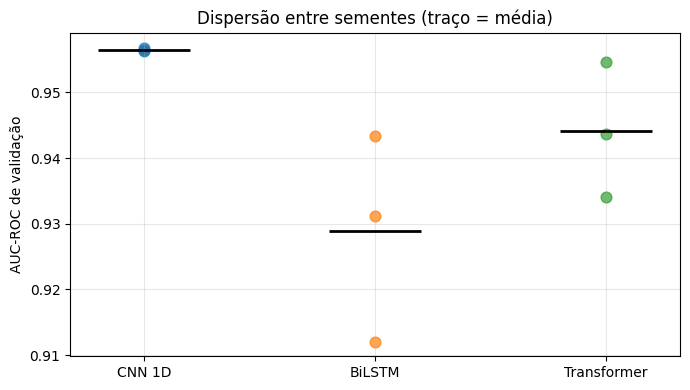

In [ ]:
# Visualizacao: AUC de cada semente + media, para ver se as faixas se sobrepoem
fig, ax = plt.subplots(figsize=(7, 4))
for i, slug in enumerate(VENCEDORAS):
    aucs = [v['auc_val'] for v in res_sem.values() if v['slug'] == slug]
    ax.scatter([i] * len(aucs), aucs, s=60, alpha=0.7, label=NOMES[slug])
    ax.hlines(np.mean(aucs), i - 0.2, i + 0.2, colors='k', lw=2)
ax.set_xticks(range(len(VENCEDORAS)))
ax.set_xticklabels([NOMES[s] for s in VENCEDORAS])
ax.set_ylabel('AUC-ROC de validação'); ax.set_title('Dispersão entre sementes (traço = média)')
FIG_DIR = f'{DATA_DIR}/figuras'; os.makedirs(FIG_DIR, exist_ok=True)
ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig(f'{FIG_DIR}/dispersao_sementes.png', dpi=300); plt.show()

## 6. Leitura dos resultados

Quando as faixas entre o menor e o maior valor de duas arquiteturas se sobrepõem, a diferença entre elas não é consistente entre as sementes, e as duas são tratadas como equivalentes. Com três sementes, os resultados descrevem a variabilidade, mas não permitem testes de significância.

Na validação, a CNN teve a maior AUC-ROC com as três sementes. A ordem entre o Transformer e a BiLSTM mudou conforme a semente: com a semente 42, o Transformer ficou à frente; com a 123, a BiLSTM (Figura 11 do TCC).

## Próximo passo

O notebook 06 avalia os nove modelos no conjunto de teste.